In [51]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions


plt.rcParams.update({'font.size': 14})


In [ ]:
# creating a dataframe of all of the annotator profiles
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

In [13]:
questions

{'Sentiment refers to the emotional tone or attitude expressed in a piece of text, typically categorized as positive, negative,or neutral based on the conveyed feelings or opinions.<b>Example</b>"The address has been updated" has neutral sentiment.You are using a language model like ChatGPT to determine the sentiment of a text [TEXT] into one of possible <b>three sentiment labels: positive, negative, and neutral</b>. How would you phrase your request to the language model? <b>Your response must include the placeholder [TEXT].</b>': {'clean': 'Sentiment refers to the emotional tone or attitude expressed in a piece of text, typically categorized as positive, negative,or neutral based on the conveyed feelings or opinions.\n\nExample\n"The address has been updated" has neutral sentiment.\n\nYou are using a language model like ChatGPT to determine the sentiment of a text [TEXT] into one of possible three sentiment labels: positive, negative, and neutral.\n\nHow would you phrase your request

In [21]:

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)

    task_group_stats = {}
    task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
    for tt in task_types: 
        prompt_lengths = []
        prompt_type_freq_table = {
            f"{tt}-imperative" : 0,
            f"{tt}-interrogative" : 0,
            f"{tt}-declarative" : 0,
        }
        prompt_grammaticality = {
            f"{tt}-grammar_correct" : 0,
            f"{tt}-grammar_incorrect" : 0,
        }
        for q, v in annotator_object["answers"].items():
            if v["answer"] and questions[q]['question_type'] == tt:
                prompt_lengths.append(v["sentence_length"])
                prompt_type_freq_table[f"{tt}-{v["sentence_type"]}"] += 1
                prompt_grammaticality[f"{tt}-grammar_{v["grammaticality"]}"] += 1
        
        task_group_stats[f"{tt}-sum_sentence_lengths"] = sum(prompt_lengths)
        task_group_stats.update(prompt_type_freq_table)
        task_group_stats.update(prompt_grammaticality)

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        **task_group_stats
    })

df_list = sorted(df_list, key=lambda x: x["id"])
df = pd.DataFrame(df_list)

In [22]:
df

,id,employment_sector,race,education,sex,age,language,nationality_group,mt_and_summarization-sum_sentence_lengths,mt_and_summarization-imperative,...,semantics-interrogative,semantics-declarative,semantics-grammar_correct,semantics-grammar_incorrect,qa_extraction-sum_sentence_lengths,qa_extraction-imperative,qa_extraction-interrogative,qa_extraction-declarative,qa_extraction-grammar_correct,qa_extraction-grammar_incorrect
0,0,Humanities,White,Graduate,female,31-40,L1,North America,8,2,...,0,0,4,0,20,2,0,0,2,0
1,1,Humanities,Asian,Postgraduate,female,18-30,None,North America,5,2,...,1,0,2,0,40,3,0,0,3,0
2,2,Humanities,White,Graduate,female,18-30,None,North America,14,2,...,3,0,4,1,52,2,1,0,2,1
3,3,Engineering-STEM,White,Graduate,female,31-40,L1,Europe,18,1,...,3,0,3,1,15,2,1,0,2,1
4,4,Humanities,White,Graduate,female,41-50,L1,North America,10,2,...,4,0,4,1,62,2,1,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,100,Engineering-STEM,White,Graduate,male,41-50,None,North America,10,1,...,0,0,3,1,90,3,0,0,3,0
95,101,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,5,2,...,1,0,3,2,57,2,1,0,3,0
96,103,Engineering-STEM,White,Graduate,male,41-50,L1,Europe,10,0,...,3,0,4,0,32,1,1,0,2,0
97,104,Engineering-STEM,White,Graduate,male,41-50,L1,North America,19,1,...,0,2,3,1,0,0,0,0,0,0


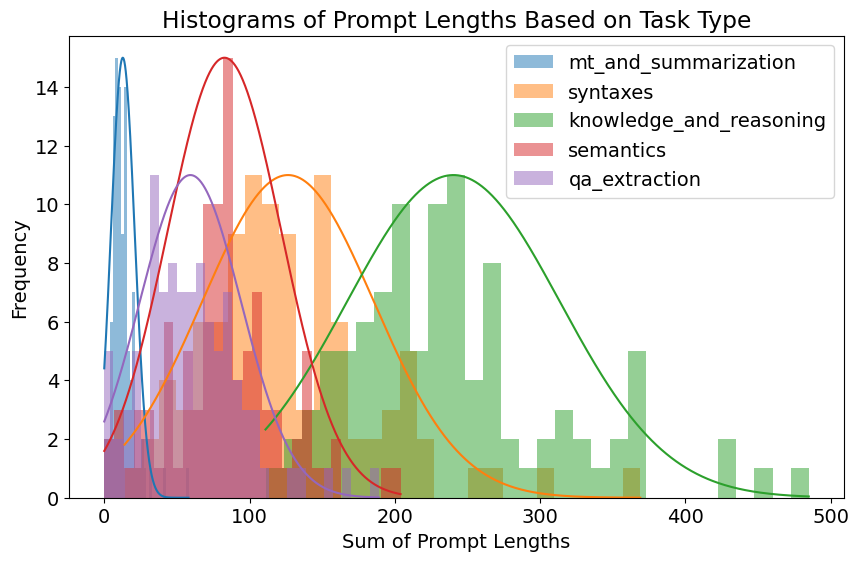

In [52]:
# for prompt length make histogram of 5 task types overlay each other
cols = df.columns[df.columns.str.contains("sum_sentence_lengths")]
plt.figure(figsize=(10, 6))

for col in cols:
    values = df[col].dropna()
    counts, bin_edges, _ = plt.hist(values, bins=30, alpha=0.5, label=col.replace("-sum_sentence_lengths", "").strip())

    mu, std = np.mean(values), np.std(values)
    x = np.linspace(bin_edges[0], bin_edges[-1], 1000)
    p = norm.pdf(x, mu, std)
    scale = max(counts) / np.max(p)

    # Get the current color used for the histogram
    color = plt.gca().patches[-1].get_facecolor()
    plt.plot(x, p * scale, color=color, alpha=1)

plt.legend()
plt.xlabel('Sum of Prompt Lengths')
plt.ylabel('Frequency')
plt.title('Histograms of Prompt Lengths Based on Task Type')
plt.show()

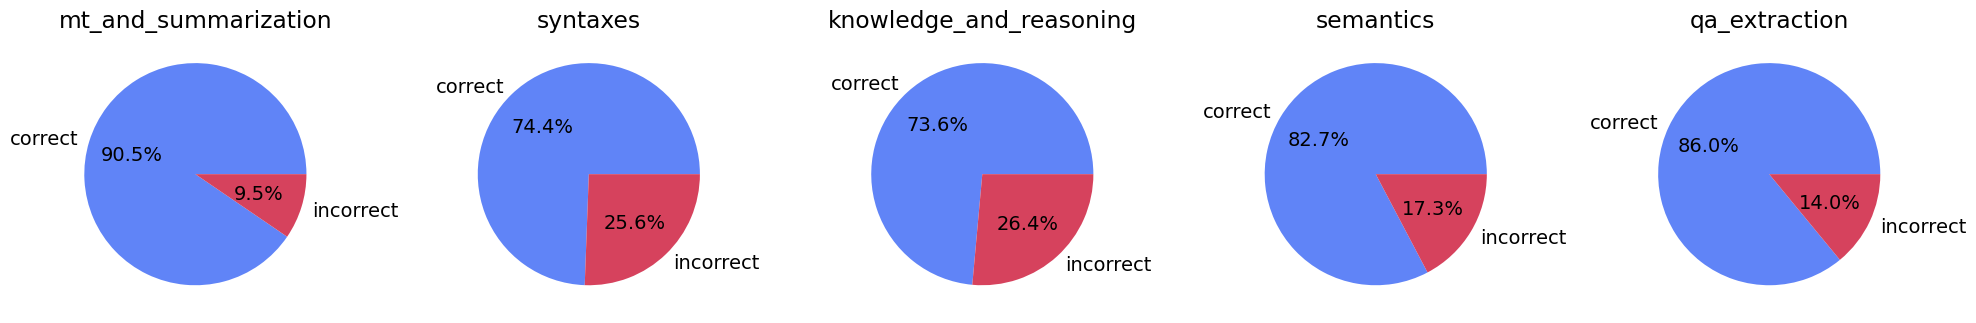

In [57]:
colors = ['#6084f7', '#d6425d']  # blue, orange, red
keywords = ["grammar_correct", "grammar_incorrect"]
pattern = "|".join(keywords)
cols = df.columns[df.columns.str.contains(pattern)]
s = df[cols].sum(axis=0)

# Group the data by prefix
grouped = {}
for k, v in s.items():
    prefix, label = k.split('-', 1)
    grouped.setdefault(prefix, {})[label] = v

# One row of pie charts
n = len(grouped)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

for ax, (prefix, data) in zip(axes, grouped.items()):
    ax.pie(data.values(), labels=[d.replace("grammar_", "") for d in data.keys()], autopct='%1.1f%%', colors=colors)
    ax.set_title(prefix)

plt.tight_layout()
plt.show()

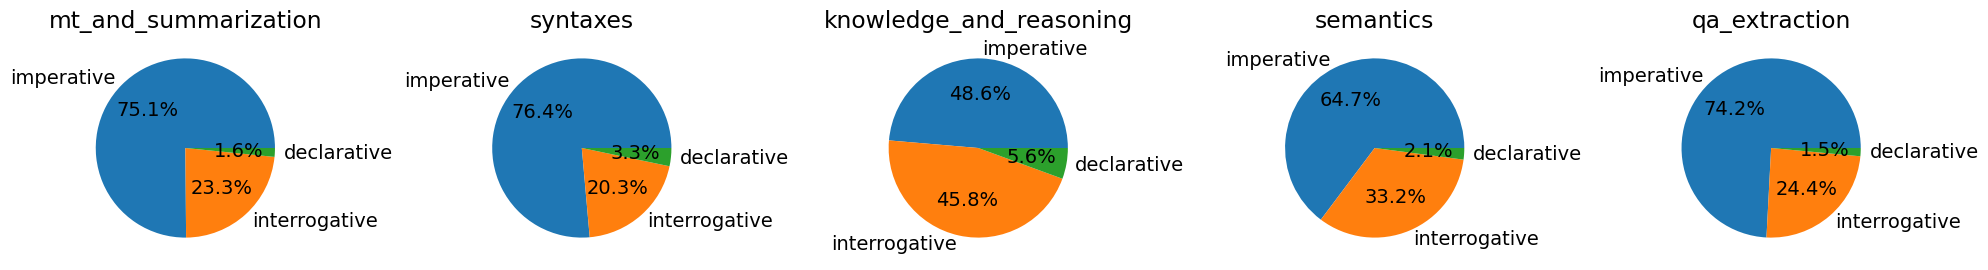

In [59]:

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
keywords = ["imperative", "interrogative", "declarative"]
pattern = "|".join(keywords)
cols = df.columns[df.columns.str.contains(pattern)]
s = df[cols].sum(axis=0)

# Group the data by prefix
grouped = {}
for k, v in s.items():
    prefix, label = k.split('-', 1)
    grouped.setdefault(prefix, {})[label] = v

# One row of pie charts
n = len(grouped)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

for ax, (prefix, data) in zip(axes, grouped.items()):
    ax.pie(data.values(), labels=data.keys(), autopct='%1.1f%%', colors=colors)
    ax.set_title(prefix)

plt.tight_layout()
plt.show()

In [23]:
# aggregates = {
#     "sum_sentence_lengths": {
#         "employment_sector" : [...],
#         "race" : [...],
#         "education" : [...],
#     },
#     "interrogative",
#     imperative	interrogative	declarative	grammar_correct	grammar_incorrect
# }
# aggregates:

profile_columns = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in profile_columns:
    for group_value, group_df in df.groupby(pc):
        print(f"\nGroup: {pc} = {group_value}")
        print(f"Group members = {len(group_df)}")
        others = [col for col in profile_columns if col != pc]
        for oc in others:
            top_value = group_df[oc].value_counts(normalize=True).idxmax()
            top_ratio = group_df[oc].value_counts(normalize=True).max()
            if top_ratio > 0.5:
                print(f"  Column {oc} dominated by '{top_value}' with {top_ratio:.2f}")


Group: employment_sector = Engineering-STEM
Group members = 38
  Column sex dominated by 'male' with 0.58
  Column language dominated by 'L1' with 0.57

Group: employment_sector = Health-STEM
Group members = 26
  Column race dominated by 'White' with 0.60
  Column education dominated by 'Postgraduate' with 0.58
  Column sex dominated by 'female' with 0.73
  Column language dominated by 'L1' with 1.00

Group: employment_sector = Humanities
Group members = 35
  Column race dominated by 'White' with 0.52
  Column sex dominated by 'male' with 0.51
  Column language dominated by 'L1' with 0.59

Group: race = Asian
Group members = 26
  Column employment_sector dominated by 'Engineering-STEM' with 0.58
  Column sex dominated by 'male' with 0.65
  Column age dominated by '18-30' with 0.85
  Column language dominated by 'L2' with 0.87
  Column nationality_group dominated by 'Asia' with 0.72

Group: race = Black
Group members = 18
  Column education dominated by 'Postgraduate' with 0.89
  Colum

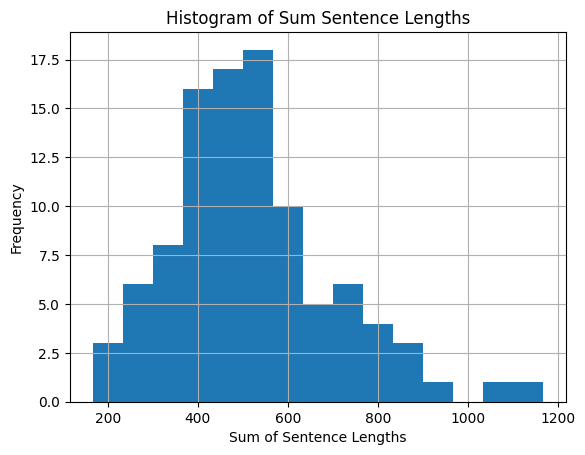

In [5]:
df['sum_sentence_lengths'].hist(bins=15)
plt.xlabel('Sum of Sentence Lengths')
plt.ylabel('Frequency')
plt.title('Histogram of Sum Sentence Lengths')
plt.show()